**Data extraction from dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Classroom', 'CO1_Fundamentals of Computers_Lecture1.gdoc', 'FSWD_Activity Set#1_HTML.docx', 'CO2_Intro_to_C_Lecture2&3.gdoc', 'Colab Notebooks', 'DS_CA_Session1 (3).1_RVU.gdoc', 'DS_CA_Session1 (2).1_RVU.gdoc', 'DS_CA_Session1 (1).1_RVU.gdoc', 'DS_CA_Session1.1_RVU.gdoc', 'C03As2P4.c', 'Co-4 and Co-5.pptx', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'Charging and Discharging of a capacitor in a RC circuit.gdoc', 'Untitled document (1).gdoc', 'Practise (1).c', 'Practise.c', 'Project presentation  template.pptx', 'Circuitrix-Light Up RVU-Fisrt slide format.gslides', 'Co-1 and Co-2.gslides', 'Co-3 (1).gslides', 'Section-B.gdoc', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (5).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (4).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (3).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (2).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (1).pptx', '_Circu

In [ ]:
dataset_path = "/content/drive/MyDrive/IEMOCAP dataset"
print(os.listdir(dataset_path))

['IEMOCAP_full_release_withoutVideos.tar.gz', 'IEMOCAP_X_all.npy', 'IEMOCAP_y_all.npy']


In [ ]:
!pip install librosa soundfile

In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm

In [ ]:
dataset_path = "/content/drive/MyDrive/IEMOCAP dataset"

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/IEMOCAP dataset"

print("Top level folders:")
print(os.listdir(dataset_path))

Top level folders:
['IEMOCAP_full_release_withoutVideos.tar.gz', 'IEMOCAP_X_all.npy', 'IEMOCAP_y_all.npy']


In [ ]:
!tar -xvzf "/content/drive/MyDrive/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos.tar.gz" -C /content/

Streaming output truncated to the last 5000 lines.
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M030.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M021.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F007.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F003.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M033.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F013.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F022.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M012.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M016.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses0

In [ ]:
dataset_path = "/content/IEMOCAP_full_release"

In [ ]:
!ls /content/IEMOCAP_full_release

Documentation  README.txt~  Session2  Session4
README.txt     Session1     Session3  Session5


In [ ]:
import os
import re
import librosa
import IPython.display as ipd

dataset_path = "/content/IEMOCAP_full_release"

# Step 1: Get one WAV file from Session1
wav_dir = os.path.join(dataset_path, "Session1", "sentences", "wav")
subfolders = os.listdir(wav_dir)

first_folder = os.path.join(wav_dir, subfolders[0])
wav_files = [f for f in os.listdir(first_folder) if f.endswith(".wav")]

wav_file = os.path.join(first_folder, wav_files[0])
print("Sample file:", wav_file)

# Step 2: Extract file ID
file_id = os.path.basename(wav_file).replace(".wav", "")
print("File ID:", file_id)

# Step 3: Find emotion label from annotation file
emo_eval_path = os.path.join(
    dataset_path,
    "Session1",
    "dialog",
    "EmoEvaluation"
)

emotion_label = None

for txt_file in os.listdir(emo_eval_path):
    if txt_file.endswith(".txt"):
        with open(os.path.join(emo_eval_path, txt_file), "r") as f:
            lines = f.readlines()
            for line in lines:
                if file_id in line:
                    match = re.search(r"\] (\S+) (\w+)", line)
                    if match:
                        emotion_label = match.group(2)
                        break
    if emotion_label:
        break

print("Emotion Label:", emotion_label)

# Step 4: Play audio
signal, sr = librosa.load(wav_file, sr=16000)
ipd.display(ipd.Audio(signal, rate=sr))

Sample file: /content/IEMOCAP_full_release/Session1/sentences/wav/Ses01F_script01_2/Ses01F_script01_2_M016.wav
File ID: Ses01F_script01_2_M016
Emotion Label: None


In [ ]:
import os

file_id = os.path.basename(wav_file).replace(".wav", "")
print("File ID:", file_id)

# Convert Ses01 → Session1
session_number = int(file_id[3:5])
session_folder = f"Session{session_number}"

# IMPORTANT FIX HERE
dialog_id = "_".join(file_id.split("_")[:3]) + ".txt"

annotation_file = os.path.join(
    dataset_path,
    session_folder,
    "dialog",
    "EmoEvaluation",
    dialog_id
)

print("Annotation file:", annotation_file)

emotion_label = None

with open(annotation_file, "r") as f:
    for line in f:
        if file_id in line:
            parts = line.strip().split()
            emotion_label = parts[4]
            break

print("Emotion Label:", emotion_label)

File ID: Ses01F_script01_2_M016
Annotation file: /content/IEMOCAP_full_release/Session1/dialog/EmoEvaluation/Ses01F_script01_2.txt
Emotion Label: xxx


In [ ]:
!pip install librosa tqdm

In [ ]:
import os
import numpy as np
import librosa
import re
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [ ]:
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

X = []
y = []

for session in range(1, 6):

    session_folder = f"Session{session}"
    wav_root = os.path.join(dataset_path, session_folder, "sentences", "wav")
    emo_root = os.path.join(dataset_path, session_folder, "dialog", "EmoEvaluation")

    for dialog in os.listdir(wav_root):

        dialog_path = os.path.join(wav_root, dialog)

        for wav_file in os.listdir(dialog_path):

            if not wav_file.endswith(".wav"):
                continue

            file_id = wav_file.replace(".wav", "")
            parts = file_id.split("_")

            # 🔥 FIX: Handle improvised vs scripted
            if "impro" in file_id:
                dialog_id = "_".join(parts[:2]) + ".txt"
            else:
                dialog_id = "_".join(parts[:3]) + ".txt"

            annotation_file = os.path.join(emo_root, dialog_id)

            if not os.path.exists(annotation_file):
                continue

            emotion_label = None

            with open(annotation_file, "r") as f:
                for line in f:
                    if file_id in line:
                        emotion_label = line.strip().split()[4]
                        break

            if emotion_label not in valid_emotions:
                continue

            # Merge excited with happy
            if emotion_label == "exc":
                emotion_label = "hap"

            wav_path = os.path.join(dialog_path, wav_file)

            # Load audio
            signal, sr = librosa.load(wav_path, sr=16000)

            # Extract MFCC
            mfcc = librosa.feature.mfcc(
                y=signal,
                sr=sr,
                n_mfcc=40
            )

            # Mean over time
            mfcc = np.mean(mfcc.T, axis=0)

            X.append(mfcc)
            y.append(emotion_label)

print("Total samples collected:", len(X))

Total samples collected: 5531


In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm
import torch
import torch.nn as nn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [ ]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X = np.array(X)
y_encoded = np.array(y_encoded)

print("Classes:", le.classes_)
print("Feature shape:", X.shape)

Classes: ['ang' 'hap' 'neu' 'sad']
Feature shape: (5531, 40)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

**MFCC + MlP model**

In [ ]:
epochs = 25

for epoch in range(epochs):

    model.train()

    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    _, predicted = torch.max(outputs, 1)
    train_acc = (predicted == y_train).float().mean()

    print(f"Epoch {epoch+1}/{epochs} | Loss: {loss.item():.4f} | Train Acc: {train_acc:.4f}")

Epoch 1/25 | Loss: 1.4886 | Train Acc: 0.2624
Epoch 2/25 | Loss: 1.3248 | Train Acc: 0.3766
Epoch 3/25 | Loss: 1.2501 | Train Acc: 0.4200
Epoch 4/25 | Loss: 1.2082 | Train Acc: 0.4433
Epoch 5/25 | Loss: 1.2068 | Train Acc: 0.4600
Epoch 6/25 | Loss: 1.1842 | Train Acc: 0.4645
Epoch 7/25 | Loss: 1.1684 | Train Acc: 0.4695
Epoch 8/25 | Loss: 1.1410 | Train Acc: 0.4930
Epoch 9/25 | Loss: 1.1331 | Train Acc: 0.5023
Epoch 10/25 | Loss: 1.1299 | Train Acc: 0.5113
Epoch 11/25 | Loss: 1.1125 | Train Acc: 0.5072
Epoch 12/25 | Loss: 1.0996 | Train Acc: 0.5115
Epoch 13/25 | Loss: 1.0951 | Train Acc: 0.5274
Epoch 14/25 | Loss: 1.0863 | Train Acc: 0.5237
Epoch 15/25 | Loss: 1.0868 | Train Acc: 0.5188
Epoch 16/25 | Loss: 1.0780 | Train Acc: 0.5269
Epoch 17/25 | Loss: 1.0739 | Train Acc: 0.5255
Epoch 18/25 | Loss: 1.0711 | Train Acc: 0.5240
Epoch 19/25 | Loss: 1.0727 | Train Acc: 0.5337
Epoch 20/25 | Loss: 1.0722 | Train Acc: 0.5353
Epoch 21/25 | Loss: 1.0633 | Train Acc: 0.5353
Epoch 22/25 | Loss: 1.

In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(X_test)
    _, predicted = torch.max(outputs, 1)
    test_acc = (predicted == y_test).float().mean()

print("Test Accuracy:", test_acc.item())

Test Accuracy: 0.5411020517349243


**Test Accuracy: 0.5411020517349243**

In [ ]:
!pip install librosa tqdm

In [ ]:
import os
import numpy as np
import librosa
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [ ]:
def extract_log_mel(file_path, sr=16000, duration=4, n_mels=128):

    samples = sr * duration

    signal, sr = librosa.load(file_path, sr=sr)

    if len(signal) > samples:
        signal = signal[:samples]
    else:
        signal = np.pad(signal, (0, samples - len(signal)))

    mel = librosa.feature.melspectrogram(
        y=signal,
        sr=sr,
        n_mels=n_mels
    )

    log_mel = librosa.power_to_db(mel, ref=np.max)

    return log_mel

In [ ]:
dataset_path = "/content/IEMOCAP_full_release"
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

X = []
y = []

for session in range(1, 6):

    session_folder = f"Session{session}"
    wav_root = os.path.join(dataset_path, session_folder, "sentences", "wav")
    emo_root = os.path.join(dataset_path, session_folder, "dialog", "EmoEvaluation")

    for dialog in os.listdir(wav_root):

        dialog_path = os.path.join(wav_root, dialog)

        for wav_file in os.listdir(dialog_path):

            if not wav_file.endswith(".wav"):
                continue

            file_id = wav_file.replace(".wav", "")
            parts = file_id.split("_")

            if "impro" in file_id:
                dialog_id = "_".join(parts[:2]) + ".txt"
            else:
                dialog_id = "_".join(parts[:3]) + ".txt"

            annotation_file = os.path.join(emo_root, dialog_id)

            if not os.path.exists(annotation_file):
                continue

            emotion_label = None

            with open(annotation_file, "r") as f:
                for line in f:
                    if file_id in line:
                        emotion_label = line.strip().split()[4]
                        break

            if emotion_label not in valid_emotions:
                continue

            if emotion_label == "exc":
                emotion_label = "hap"

            wav_path = os.path.join(dialog_path, wav_file)

            feature = extract_log_mel(wav_path)

            X.append(feature)
            y.append(emotion_label)

print("Total samples:", len(X))

Total samples: 5531


In [ ]:
!ls /content/IEMOCAP_dataset/

ls: cannot access '/content/IEMOCAP_dataset/': No such file or directory


In [ ]:
!ls /content/IEMOCAP_dataset/Session1/

ls: cannot access '/content/IEMOCAP_dataset/Session1/': No such file or directory


In [ ]:
!tar -tf /content/drive/MyDrive/IEMOCAP_full_release_withoutVideos.tar.gz | head -20

tar: /content/drive/MyDrive/IEMOCAP_full_release_withoutVideos.tar.gz: Cannot open: No such file or directory
tar: Error is not recoverable: exiting now


In [ ]:
!ls /content/IEMOCAP_dataset/

IEMOCAP_full_release


In [ ]:
dataset_path = "/content/IEMOCAP_dataset/IEMOCAP_full_release"

In [ ]:
for session in range(1, 6):
    sess_path = os.path.join(dataset_path, f"Session{session}")
    if not os.path.exists(sess_path):
        print(f"Session folder not found: {sess_path}")
        continue
    # ... rest of your code ...

Session folder not found: /content/IEMOCAP_dataset/IEMOCAP_full_release/Session1
Session folder not found: /content/IEMOCAP_dataset/IEMOCAP_full_release/Session2
Session folder not found: /content/IEMOCAP_dataset/IEMOCAP_full_release/Session3
Session folder not found: /content/IEMOCAP_dataset/IEMOCAP_full_release/Session4
Session folder not found: /content/IEMOCAP_dataset/IEMOCAP_full_release/Session5


In [ ]:
import os

# Replace with the actual folder where you saved IEMOCAP
drive_folder = "/content/drive/MyDrive"
print(os.listdir(drive_folder))

['Classroom', 'CO1_Fundamentals of Computers_Lecture1.gdoc', 'FSWD_Activity Set#1_HTML.docx', 'CO2_Intro_to_C_Lecture2&3.gdoc', 'Colab Notebooks', 'DS_CA_Session1 (3).1_RVU.gdoc', 'DS_CA_Session1 (2).1_RVU.gdoc', 'DS_CA_Session1 (1).1_RVU.gdoc', 'DS_CA_Session1.1_RVU.gdoc', 'C03As2P4.c', 'Co-4 and Co-5.pptx', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'Charging and Discharging of a capacitor in a RC circuit.gdoc', 'Untitled document (1).gdoc', 'Practise (1).c', 'Practise.c', 'Project presentation  template.pptx', 'Circuitrix-Light Up RVU-Fisrt slide format.gslides', 'Co-1 and Co-2.gslides', 'Co-3 (1).gslides', 'Section-B.gdoc', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (5).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (4).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (3).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (2).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (1).pptx', '_Circu

In [ ]:
!pip install transformers datasets librosa soundfile

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

#
from google.colab import drive
drive.mount('/content/drive')

#
print("MyDrive contents:")
print(os.listdir('/content/drive/MyDrive'))

#
dataset_folder = "/content/drive/MyDrive/IEMOCAP dataset"

if os.path.exists(dataset_folder):
    print("\nIEMOCAP dataset folder contents:")
    print(os.listdir(dataset_folder))
else:
    print("\nFolder not found:", dataset_folder)

#
archive_path = os.path.join(dataset_folder, "IEMOCAP_full_release_withoutVideos.tar.gz")

if os.path.exists(archive_path):
    print("\nTar file FOUND at:")
    print(archive_path)
else:
    print("\nTar file NOT found at expected path.")

# =
if os.path.exists("/content/IEMOCAP_full_release"):
    print("\nDataset already extracted at /content/IEMOCAP_full_release")
    print(os.listdir("/content/IEMOCAP_full_release"))
else:
    print("\nDataset NOT extracted in /content yet.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MyDrive contents:
['Classroom', 'CO1_Fundamentals of Computers_Lecture1.gdoc', 'FSWD_Activity Set#1_HTML.docx', 'CO2_Intro_to_C_Lecture2&3.gdoc', 'Colab Notebooks', 'DS_CA_Session1 (3).1_RVU.gdoc', 'DS_CA_Session1 (2).1_RVU.gdoc', 'DS_CA_Session1 (1).1_RVU.gdoc', 'DS_CA_Session1.1_RVU.gdoc', 'C03As2P4.c', 'Co-4 and Co-5.pptx', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'Charging and Discharging of a capacitor in a RC circuit.gdoc', 'Untitled document (1).gdoc', 'Practise (1).c', 'Practise.c', 'Project presentation  template.pptx', 'Circuitrix-Light Up RVU-Fisrt slide format.gslides', 'Co-1 and Co-2.gslides', 'Co-3 (1).gslides', 'Section-B.gdoc', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (5).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (4).pptx', '_Circuitrix-Light_Up_RVU-Fisrt_slide_format[1][1][1][1] (3).ppt

**Wav2Vec2 model **
(class imbalance handled using weights )


In [31]:
# ==============================================
# IEMOCAP 4-CLASS EMOTION RECOGNITION (FINAL)
# ==============================================

!pip install transformers librosa soundfile -q

import os
import glob
import torch
import librosa
import numpy as np
from collections import Counter
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset, DataLoader
from transformers import Wav2Vec2Processor, Wav2Vec2ForSequenceClassification

# -------------------------------------------------
# 1️⃣ DATA PATH
# -------------------------------------------------
DATA_PATH = "/content/IEMOCAP_full_release"

# -------------------------------------------------
# 2️⃣ Collect WAV files + labels
# -------------------------------------------------
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]
wav_paths = []
labels = []

for session in range(1, 6):
    session_path = os.path.join(DATA_PATH, f"Session{session}")
    wav_files = glob.glob(os.path.join(session_path, "**/*.wav"), recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(session_path, "dialog", "EmoEvaluation", ann_name)
        if not os.path.exists(ann_path):
            continue

        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue

        if emotion == "exc":
            emotion = "hap"

        wav_paths.append(wav_file)
        labels.append(emotion)

print("Total samples:", len(wav_paths))
print("Class distribution:", Counter(labels))

# -------------------------------------------------
# 3️⃣ Encode Labels + Split
# -------------------------------------------------
le = LabelEncoder()
y = le.fit_transform(labels)

X_train, X_test, y_train, y_test = train_test_split(
    wav_paths,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -------------------------------------------------
# 🔧 DEVICE (FIXED POSITION)
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# ⚖️ Class Imbalance Handling
# -------------------------------------------------
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y),
    y=y
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class Weights:", class_weights)

# -------------------------------------------------
# 4️⃣ Dataset Class
# -------------------------------------------------
class IemocapDataset(Dataset):
    def __init__(self, paths, labels):
        self.paths = paths
        self.labels = labels
        self.max_len = 16000 * 4

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        signal, sr = librosa.load(self.paths[idx], sr=16000)

        if len(signal) > self.max_len:
            signal = signal[:self.max_len]
        else:
            signal = np.pad(signal, (0, self.max_len - len(signal)))

        return signal, self.labels[idx]

# -------------------------------------------------
# 5️⃣ Load Model
# -------------------------------------------------
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=len(le.classes_)
).to(device)

# -------------------------------------------------
# 6️⃣ Collate Function
# -------------------------------------------------
def collate_fn(batch):
    signals, labels = zip(*batch)

    inputs = processor(
        list(signals),
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    inputs["labels"] = torch.tensor(labels)
    return inputs

train_dataset = IemocapDataset(X_train, y_train)
test_dataset = IemocapDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=8, collate_fn=collate_fn)

# -------------------------------------------------
# 7️⃣ Training
# -------------------------------------------------
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

epochs = 8

for epoch in range(epochs):
    model.train()
    total_correct = 0
    total_samples = 0

    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        logits = outputs.logits

        loss = loss_fn(logits, batch["labels"])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        preds = torch.argmax(logits, dim=1)
        total_correct += (preds == batch["labels"]).sum().item()
        total_samples += batch["labels"].size(0)

    print(f"Epoch {epoch+1}/{epochs} | Train Acc: {total_correct/total_samples:.4f}")

# -------------------------------------------------
# 8️⃣ Evaluation
# -------------------------------------------------
model.eval()
correct = 0
total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        logits = outputs.logits

        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

        correct += (preds == batch["labels"]).sum().item()
        total += batch["labels"].size(0)

print("Final Test Accuracy:", correct/total)

Total samples: 5621
Class distribution: Counter({'neu': 1755, 'hap': 1654, 'ang': 1112, 'sad': 1100})
Class Weights: tensor([1.2637, 0.8496, 0.8007, 1.2775], device='cuda:0')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.bias               | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 
projector.weight             | MISSING    | 
projector.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/8 | Train Acc: 0.4918
Epoch 2/8 | Train Acc: 0.6368
Epoch 3/8 | Train Acc: 0.7246
Epoch 4/8 | Train Acc: 0.7958
Epoch 5/8 | Train Acc: 0.8519
Epoch 6/8 | Train Acc: 0.8939
Epoch 7/8 | Train Acc: 0.9161
Epoch 8/8 | Train Acc: 0.9286
Final Test Accuracy: 0.7111111111111111



**Final Test Accuracy: 0.711**

**Emotion trend analysis**


In [45]:
!pip install pandas scipy matplotlib -q

In [53]:
# ==============================================
# 🔗 CREATE REAL CONVERSATION DATAFRAME
# ==============================================

import pandas as pd
import os
import re

records = []

for path, pred in zip(X_test, all_preds):
    filename = os.path.basename(path).replace(".wav", "")

    parts = filename.split("_")

    # Conversation ID (robust)
    if len(parts) >= 2:
        conversation_id = "_".join(parts[:2])
    else:
        conversation_id = filename

    # Robust Utterance ID extraction
    match = re.search(r'(\d+)$', filename)
    if match:
        utterance_id = int(match.group(1))
    else:
        utterance_id = 0

    emotion_label = le.inverse_transform([pred])[0]

    records.append({
        "conversation_id": conversation_id,
        "utterance_id": utterance_id,
        "emotion_label": emotion_label
    })

df = pd.DataFrame(records)

print("✅ Total Conversations:", df["conversation_id"].nunique())
print(df.head())

✅ Total Conversations: 108
   conversation_id  utterance_id emotion_label
0   Ses04F_impro07            74           hap
1  Ses03F_script02            20           ang
2   Ses05M_impro05             7           neu
3  Ses04M_script03            13           ang
4   Ses04F_impro01            21           ang


In [54]:
# ==============================================
# 📊 EMOTION TREND ANALYSIS (FINAL)
# ==============================================

import numpy as np
import json
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import os

# VAD Mapping (Valence, Arousal, Dominance)
VAD_MAP = {
    "hap": (0.8, 0.7, 0.6),
    "sad": (-0.7, 0.3, 0.4),
    "ang": (-0.6, 0.8, 0.7),
    "neu": (0.0, 0.5, 0.5)
}

os.makedirs("plots", exist_ok=True)

results = []
vad_sequences = {}

for conv_id, group in df.groupby("conversation_id"):

    group = group.sort_values("utterance_id")

    emotions = group["emotion_label"].tolist()

    # Convert to VAD
    vad_values = np.array([VAD_MAP[e] for e in emotions])

    valence = vad_values[:, 0]
    arousal = vad_values[:, 1]
    dominance = vad_values[:, 2]

    # Smooth curves
    valence_smooth = gaussian_filter1d(valence, sigma=1)
    arousal_smooth = gaussian_filter1d(arousal, sigma=1)
    dominance_smooth = gaussian_filter1d(dominance, sigma=1)

    # Statistics
    mean_valence = np.mean(valence)
    peak_valence = np.max(valence)
    min_valence = np.min(valence)
    variance = np.var(valence)

    transitions = sum(
        1 for i in range(1, len(emotions))
        if emotions[i] != emotions[i-1]
    )

    results.append({
        "conversation_id": conv_id,
        "mean_valence": mean_valence,
        "peak_valence": peak_valence,
        "min_valence": min_valence,
        "variance": variance,
        "transitions": transitions
    })

    # Store VAD
    vad_sequences[conv_id] = {
        "valence": valence.tolist(),
        "arousal": arousal.tolist(),
        "dominance": dominance.tolist()
    }

    # Plot graph
    plt.figure()
    x = range(len(valence))

    plt.plot(x, valence_smooth, linewidth=3, label="Valence")
    plt.plot(x, arousal_smooth, linestyle="--", linewidth=2, label="Arousal")
    plt.plot(x, dominance_smooth, linestyle=":", linewidth=2, label="Dominance")

    plt.xlabel("Utterance Index")
    plt.ylabel("Emotion Intensity")
    plt.title(f"Emotion Trend - {conv_id}")
    plt.legend()

    plt.savefig(f"plots/{conv_id}.png")
    plt.close()

# Save CSV
pd.DataFrame(results).to_csv("emotion_statistics.csv", index=False)

# Save JSON
with open("vad_sequences.json", "w") as f:
    json.dump(vad_sequences, f, indent=4)

print("✅ Emotion Trend Analysis Completed for ALL conversations!")

✅ Emotion Trend Analysis Completed for ALL conversations!


Sample Conversations:
['Ses01F_impro01', 'Ses01F_impro02', 'Ses01F_impro03', 'Ses01F_impro04', 'Ses01F_impro05', 'Ses01F_impro06', 'Ses01F_impro07', 'Ses01F_script01', 'Ses01F_script02', 'Ses01F_script03']

Enter Conversation ID: Ses01F_impro03


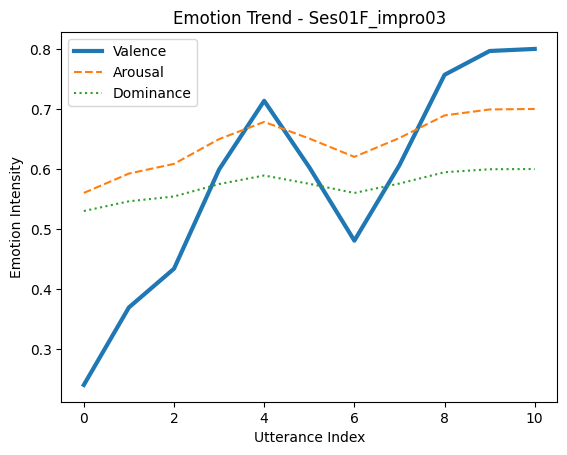


📌 Conclusion: Emotion improves towards a positive state.


In [55]:
# ==============================================
# 🎯 USER SELECTED VISUALIZATION + CONCLUSION
# ==============================================

import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Load data
with open("vad_sequences.json", "r") as f:
    vad_data = json.load(f)

# Show some IDs
print("Sample Conversations:")
print(list(vad_data.keys())[:10])

# Input
conv_id = input("\nEnter Conversation ID: ")

if conv_id not in vad_data:
    print("❌ Invalid Conversation ID")
else:
    valence = np.array(vad_data[conv_id]["valence"])
    arousal = np.array(vad_data[conv_id]["arousal"])
    dominance = np.array(vad_data[conv_id]["dominance"])

    # Smooth
    valence_smooth = gaussian_filter1d(valence, sigma=1)
    arousal_smooth = gaussian_filter1d(arousal, sigma=1)
    dominance_smooth = gaussian_filter1d(dominance, sigma=1)

    # Plot
    plt.figure()
    x = range(len(valence))

    plt.plot(x, valence_smooth, linewidth=3, label="Valence")
    plt.plot(x, arousal_smooth, linestyle="--", label="Arousal")
    plt.plot(x, dominance_smooth, linestyle=":", label="Dominance")

    plt.xlabel("Utterance Index")
    plt.ylabel("Emotion Intensity")
    plt.title(f"Emotion Trend - {conv_id}")
    plt.legend()

    plt.show()

    # 🔥 Conclusion
    trend = valence_smooth[-1] - valence_smooth[0]
    mean_dom = np.mean(dominance)

    if trend > 0.2:
        conclusion = "Emotion improves towards a positive state."
    elif trend < -0.2:
        conclusion = "Emotion declines towards a negative state."
    else:
        conclusion = "Emotion remains stable."

    if mean_dom > 0.6:
        conclusion += " Speaker shows high confidence."
    elif mean_dom < 0.4:
        conclusion += " Speaker shows low dominance."

    print("\n📌 Conclusion:", conclusion)


Total Conversations: 107


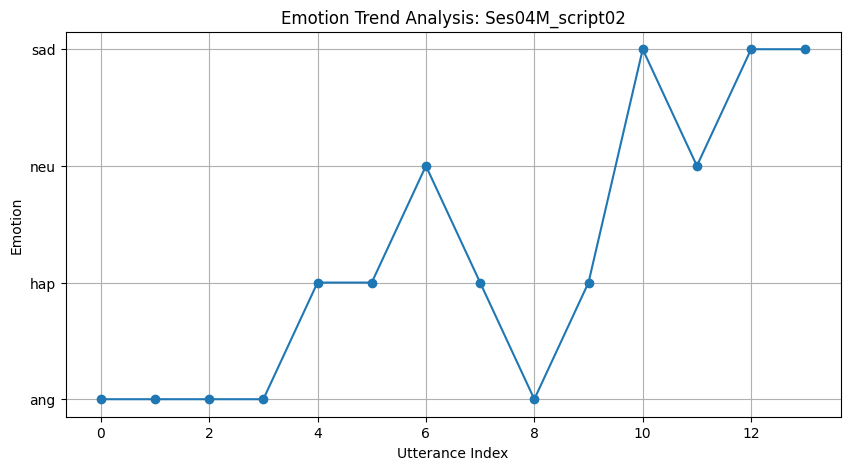

In [ ]:
# ==============================================
# 🔟 EMOTION TREND ANALYSIS (ADD THIS BELOW)
# ==============================================

from collections import defaultdict
import matplotlib.pyplot as plt

# Step 1: Get predictions for all test samples
model.eval()

all_preds = []
all_paths = []

with torch.no_grad():
    for batch_idx, batch in enumerate(test_loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())

        # Collect corresponding file paths
        start_idx = batch_idx * test_loader.batch_size
        end_idx = start_idx + len(preds)
        all_paths.extend(X_test[start_idx:end_idx])

# Step 2: Convert labels back to emotion names
predicted_emotions = le.inverse_transform(all_preds)

# Step 3: Group by conversation
conversation_emotions = defaultdict(list)

for path, emo in zip(all_paths, predicted_emotions):
    file_id = os.path.basename(path).replace(".wav", "")
    conv_id = "_".join(file_id.split("_")[:2])   # conversation id

    conversation_emotions[conv_id].append(emo)

print("\nTotal Conversations:", len(conversation_emotions))

# Step 4: Plot ONE conversation trend
import random

sample_conv = random.choice(list(conversation_emotions.keys()))
emotion_sequence = conversation_emotions[sample_conv]

# Convert emotions to numbers for plotting
emotion_to_num = {e: i for i, e in enumerate(le.classes_)}
numeric_sequence = [emotion_to_num[e] for e in emotion_sequence]

plt.figure(figsize=(10,5))
plt.plot(numeric_sequence, marker='o')

plt.yticks(list(emotion_to_num.values()), list(emotion_to_num.keys()))
plt.xlabel("Utterance Index")
plt.ylabel("Emotion")
plt.title(f"Emotion Trend Analysis: {sample_conv}")
plt.grid()

plt.show()

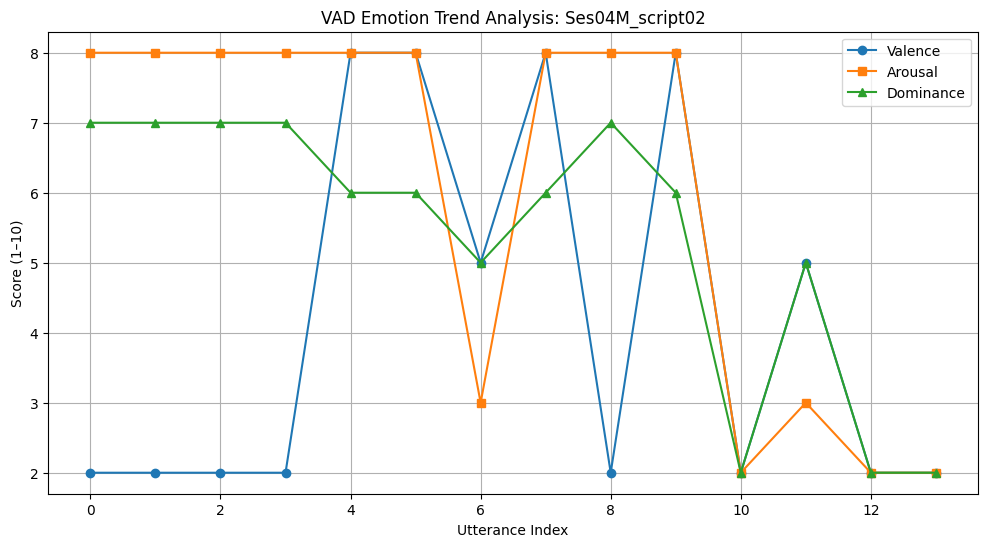

In [ ]:
# ==============================================
# 🔟 VAD / PAD BASED EMOTION TREND ANALYSIS
# ==============================================

# Step 1: Define VAD mapping
emotion_to_vad = {
    "ang": [2, 8, 7],   # low valence, high arousal, high dominance
    "hap": [8, 8, 6],   # high valence, high arousal
    "sad": [2, 2, 2],   # low valence, low arousal
    "neu": [5, 3, 5]    # neutral
}

# Step 2: Get VAD sequence for selected conversation
vad_sequence = [emotion_to_vad[e] for e in emotion_sequence]

valence = [v[0] for v in vad_sequence]
arousal = [v[1] for v in vad_sequence]
dominance = [v[2] for v in vad_sequence]

# Step 3: Plot VAD trends
plt.figure(figsize=(12,6))

plt.plot(valence, marker='o', label="Valence")
plt.plot(arousal, marker='s', label="Arousal")
plt.plot(dominance, marker='^', label="Dominance")

plt.xlabel("Utterance Index")
plt.ylabel("Score (1–10)")
plt.title(f"VAD Emotion Trend Analysis: {sample_conv}")

plt.legend()
plt.grid()

plt.show()

Total Conversations: 107

Selected Conversation: Ses02M_script02
Emotion Sequence: [np.str_('hap'), np.str_('ang'), np.str_('sad'), np.str_('hap'), np.str_('hap'), np.str_('sad'), np.str_('neu'), np.str_('neu'), np.str_('neu'), np.str_('neu'), np.str_('hap')]


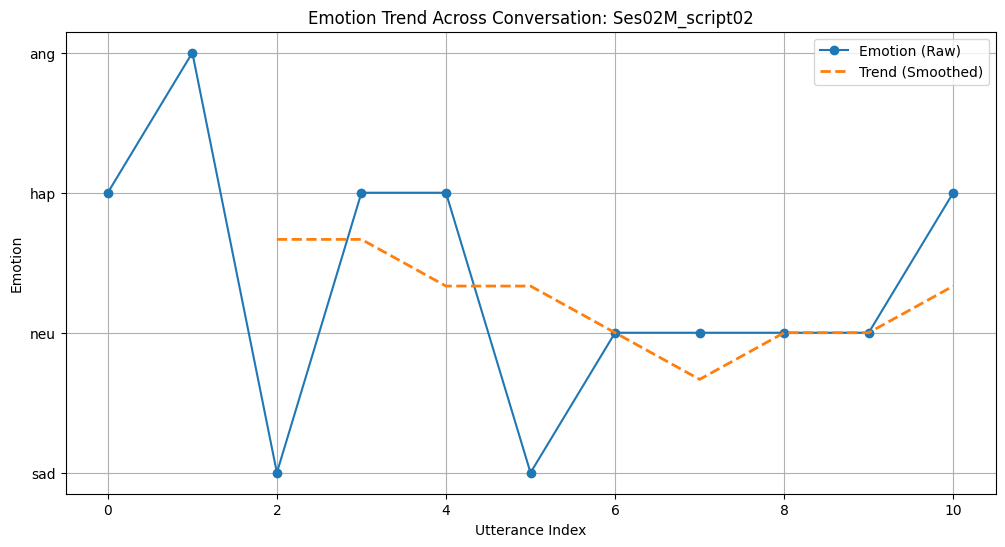

In [ ]:
# ==============================================
# 🔟 FINAL EMOTION TREND ANALYSIS (BEST VERSION)
# ==============================================

import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np

# Step 1: Collect predictions (if not already stored)
model.eval()

all_preds = []
all_paths = []

with torch.no_grad():
    for batch_idx, batch in enumerate(test_loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())

        start_idx = batch_idx * test_loader.batch_size
        end_idx = start_idx + len(preds)
        all_paths.extend(X_test[start_idx:end_idx])

# Step 2: Convert to emotion labels
predicted_emotions = le.inverse_transform(all_preds)

# Step 3: Group by conversation
conversation_emotions = defaultdict(list)

for path, emo in zip(all_paths, predicted_emotions):
    file_id = os.path.basename(path).replace(".wav", "")
    conv_id = "_".join(file_id.split("_")[:2])

    conversation_emotions[conv_id].append(emo)

print("Total Conversations:", len(conversation_emotions))

# Step 4: Select one conversation
import random
sample_conv = random.choice(list(conversation_emotions.keys()))
emotion_sequence = conversation_emotions[sample_conv]

print(f"\nSelected Conversation: {sample_conv}")
print("Emotion Sequence:", emotion_sequence)

# Step 5: Convert emotions to numeric scale
emotion_map = {
    "sad": 0,
    "neu": 1,
    "hap": 2,
    "ang": 3
}

numeric_seq = [emotion_map[e] for e in emotion_sequence]

# Step 6: Smooth trend (moving average)
window_size = 3
smoothed = np.convolve(numeric_seq, np.ones(window_size)/window_size, mode='valid')

# Step 7: Plot graph
plt.figure(figsize=(12,6))

# Raw emotion points
plt.plot(numeric_seq, marker='o', linestyle='-', label="Emotion (Raw)")

# Smoothed trend
plt.plot(range(window_size-1, len(numeric_seq)), smoothed,
         linestyle='--', linewidth=2, label="Trend (Smoothed)")

plt.yticks(
    list(emotion_map.values()),
    list(emotion_map.keys())
)

plt.xlabel("Utterance Index")
plt.ylabel("Emotion")
plt.title(f"Emotion Trend Across Conversation: {sample_conv}")

plt.legend()
plt.grid()

plt.show()

Selected Conversation: Ses04F_script02
Emotion sequence: [np.str_('ang'), np.str_('sad'), np.str_('ang'), np.str_('hap'), np.str_('hap'), np.str_('ang'), np.str_('sad'), np.str_('ang'), np.str_('sad'), np.str_('hap'), np.str_('neu'), np.str_('sad'), np.str_('hap'), np.str_('ang'), np.str_('hap'), np.str_('ang'), np.str_('sad'), np.str_('ang'), np.str_('neu'), np.str_('ang'), np.str_('ang'), np.str_('ang')]


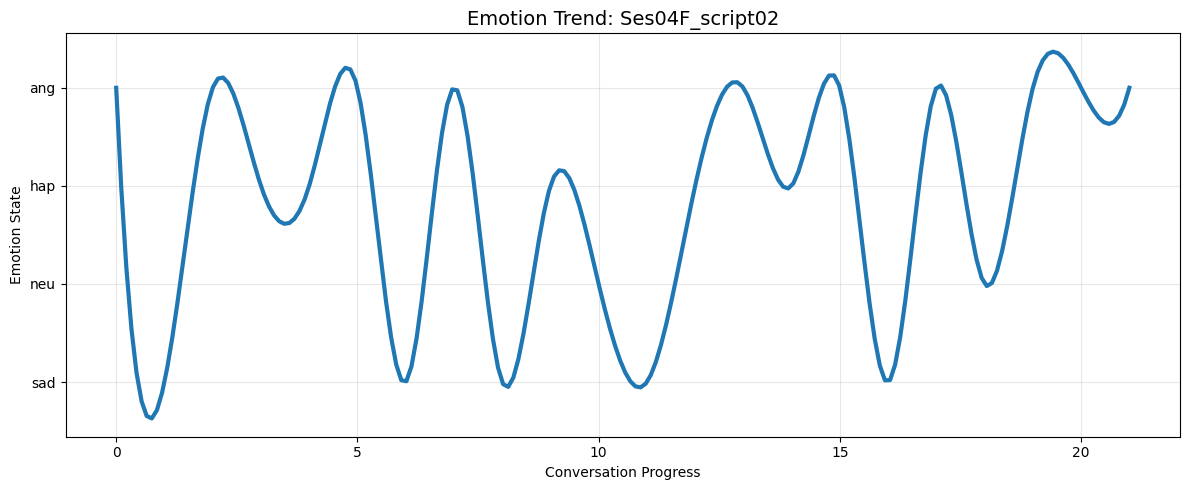

In [ ]:
# ==============================================
# 🎨 SMOOTH AESTHETIC EMOTION TREND GRAPH
# ==============================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline
from collections import defaultdict

# Step 1: Get predictions
model.eval()

all_preds = []
all_paths = []

with torch.no_grad():
    for batch_idx, batch in enumerate(test_loader):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())

        start_idx = batch_idx * test_loader.batch_size
        end_idx = start_idx + len(preds)
        all_paths.extend(X_test[start_idx:end_idx])

# Step 2: Convert to labels
predicted_emotions = le.inverse_transform(all_preds)

# Step 3: Group by conversation
conversation_emotions = defaultdict(list)

for path, emo in zip(all_paths, predicted_emotions):
    file_id = os.path.basename(path).replace(".wav", "")
    conv_id = "_".join(file_id.split("_")[:2])
    conversation_emotions[conv_id].append(emo)

#
# Pick conversation with max variation
best_conv = None
max_variety = 0

for conv, emos in conversation_emotions.items():
    unique_count = len(set(emos))
    if unique_count > max_variety and len(emos) > 5:
        max_variety = unique_count
        best_conv = conv

sample_conv = best_conv
emotion_sequence = conversation_emotions[sample_conv]

print("Selected Conversation:", sample_conv)
print("Emotion sequence:", emotion_sequence)

# Step 5: Map to numeric scale
emotion_map = {
    "sad": 0,
    "neu": 1,
    "hap": 2,
    "ang": 3
}

y = np.array([emotion_map[e] for e in emotion_sequence])
x = np.arange(len(y))

# Step 6: Smooth curve using spline
if len(x) > 3:
    x_new = np.linspace(x.min(), x.max(), 200)
    spline = make_interp_spline(x, y, k=3)
    y_smooth = spline(x_new)
else:
    x_new, y_smooth = x, y

# Step 7: Plot aesthetic graph
plt.figure(figsize=(12,5))

plt.plot(x_new, y_smooth, linewidth=3)

plt.yticks(
    list(emotion_map.values()),
    list(emotion_map.keys())
)

plt.title(f"Emotion Trend: {sample_conv}", fontsize=14)
plt.xlabel("Conversation Progress")
plt.ylabel("Emotion State")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

**Model Evaluation**

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

In [33]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

In [34]:
print("Accuracy:", accuracy_score(all_labels, all_preds))
print("Precision (weighted):", precision_score(all_labels, all_preds, average='weighted'))
print("Recall (weighted):", recall_score(all_labels, all_preds, average='weighted'))
print("F1-score (weighted):", f1_score(all_labels, all_preds, average='weighted'))

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=le.classes_))

Accuracy: 0.7111111111111111
Precision (weighted): 0.7220340534348961
Recall (weighted): 0.7111111111111111
F1-score (weighted): 0.7081980992853713

Classification Report:

              precision    recall  f1-score   support

         ang       0.70      0.88      0.78       223
         hap       0.80      0.57      0.67       331
         neu       0.64      0.72      0.68       351
         sad       0.76      0.73      0.75       220

    accuracy                           0.71      1125
   macro avg       0.72      0.73      0.72      1125
weighted avg       0.72      0.71      0.71      1125



In [35]:
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[196   2  23   2]
 [ 43 189  80  19]
 [ 36  31 254  30]
 [  6  15  38 161]]


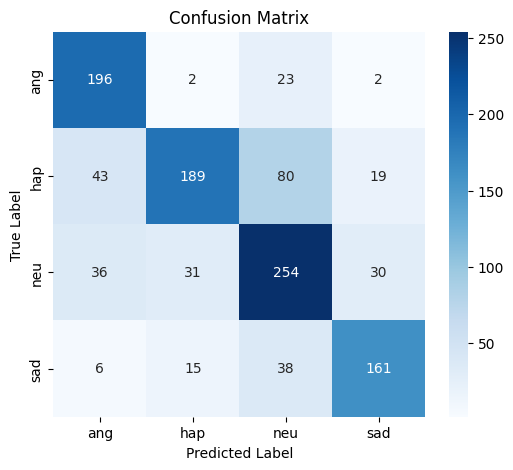

In [36]:
plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

In [38]:
model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)

        probs = torch.softmax(outputs.logits, dim=1)

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

In [39]:
n_classes = len(le.classes_)

y_test_bin = label_binarize(all_labels, classes=np.arange(n_classes))

In [40]:
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

In [41]:
fpr["micro"], tpr["micro"], _ = roc_curve(
    y_test_bin.ravel(),
    all_probs.ravel()
)
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

In [42]:
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

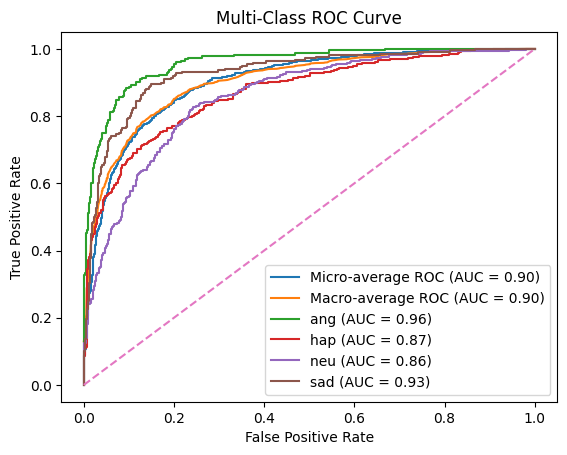

In [43]:
plt.figure()

# Micro-average
plt.plot(
    fpr["micro"],
    tpr["micro"],
    label=f"Micro-average ROC (AUC = {roc_auc['micro']:.2f})"
)

# Macro-average
plt.plot(
    fpr["macro"],
    tpr["macro"],
    label=f"Macro-average ROC (AUC = {roc_auc['macro']:.2f})"
)

# Per-class curves
for i in range(n_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{le.classes_[i]} (AUC = {roc_auc[i]:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend()
plt.show()

In [44]:
print("\nPer-class AUC:")
for i in range(n_classes):
    print(f"{le.classes_[i]}: {roc_auc[i]:.4f}")

print("\nMicro-average AUC:", roc_auc["micro"])
print("Macro-average AUC:", roc_auc["macro"])


Per-class AUC:
ang: 0.9568
hap: 0.8702
neu: 0.8578
sad: 0.9274

Micro-average AUC: 0.9014895144032923
Macro-average AUC: 0.9036334325560914
